# Credit Card Fraud Detection

An end-to-end comparison of supervised and anomaly-detection models for a highly imbalanced fraud classification problem.

**Dataset:** [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)  
**Target:** `Class` (`0` = legitimate transaction, `1` = fraudulent transaction)


## Workflow

1. Explore data quality, class imbalance and transaction patterns.
2. Create time-based features and prevent data leakage during preprocessing.
3. Compare Random Forest + SMOTE, Isolation Forest and XGBoost.
4. Select configurations with validation data, then evaluate them with 10-fold cross-validation.
5. Compare paired PR-AUC results with the Wilcoxon signed-rank test and report hold-out test performance.

## Problem Definition

The model estimates whether an individual credit card transaction is legitimate or fraudulent. This is a binary classification task, but it is extremely imbalanced: fraudulent transactions account for only about 0.17% of the dataset.

A positive prediction is best interpreted as a signal for additional review, rather than an automatic rejection. Because missing fraud is costly, the evaluation prioritises recall, F2-score and PR-AUC over accuracy.

# Data Preparation


In [104]:
# Importy
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, train_test_split

from sklearn.preprocessing import RobustScaler

from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    classification_report,
    fbeta_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

## 1. Exploratory Data Analysis


In [105]:
RANDOM_STATE = 42

In [106]:
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.4f}".format)

In [107]:
DATA_PATH = Path("data/creditcard.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("creditcard.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/creditcard.csv")

df = pd.read_csv(DATA_PATH)

In [108]:
print(f"Wymiary zbioru: {df.shape[0]:,} wierszy x {df.shape[1]} kolumn")

Wymiary zbioru: 284,807 wierszy x 31 kolumn


In [109]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [110]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [111]:
class_counts = df["Class"].value_counts().sort_index()
class_summary = pd.DataFrame({
    "liczba obserwacji": class_counts,
    "%": (class_counts / len(df) * 100).round(4),
}).rename(index={0: "legalna", 1: "oszustwo"})
display(class_summary)

,liczba obserwacji,%
Class,,
legalna,284315,99.8273
oszustwo,492,0.1727


In [112]:
print(f"Łączna liczba braków danych: {df.isna().sum().sum()}")

Łączna liczba braków danych: 0


In [113]:
print(f"Liczba pełnych duplikatów wierszy: {df.duplicated().sum()}")

Liczba pełnych duplikatów wierszy: 1081


In [114]:
df.groupby("Class")["Amount"].describe().rename(index={0: "legalna", 1: "oszustwo"})

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
legalna,"284,315.0000",88.2910,250.1051,0.0000,5.6500,22.0000,77.0500,"25,691.1600"
oszustwo,492.0000,122.2113,256.6833,0.0000,1.0000,9.2500,105.8900,"2,125.8700"


In [115]:
display(df[["Time", "Amount", "Class"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
Time,"284,807.0000","94,813.8596","47,488.1460",0.0000,"54,201.5000","84,692.0000","139,320.5000","172,792.0000"
Amount,"284,807.0000",88.3496,250.1201,0.0000,5.6000,22.0000,77.1650,"25,691.1600"
Class,"284,807.0000",0.0017,0.0415,0.0000,0.0000,0.0000,0.0000,1.0000


In [116]:
amount_by_class = df.groupby("Class")["Amount"].agg(
    count="count", mean="mean", median="median", std="std", min="min", max="max"
).rename(index={0: "legalna", 1: "oszustwo"})
amount_by_class

,count,mean,median,std,min,max
Class,,,,,,
legalna,284315,88.2910,22.0000,250.1051,0.0000,"25,691.1600"
oszustwo,492,122.2113,9.2500,256.6833,0.0000,"2,125.8700"


In [117]:
pca_columns = [col for col in df.columns if col.startswith("V")]
display(df[pca_columns].describe())

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28
count,"284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000","284,807.0000"
mean,0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000,-0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,-0.0000
std,1.9587,1.6513,1.5163,1.4159,1.3802,1.3323,1.2371,1.1944,1.0986,1.0888,1.0207,0.9992,0.9953,0.9586,0.9153,0.8763,0.8493,0.8382,0.8140,0.7709,0.7345,0.7257,0.6245,0.6056,0.5213,0.4822,0.4036,0.3301
min,-56.4075,-72.7157,-48.3256,-5.6832,-113.7433,-26.1605,-43.5572,-73.2167,-13.4341,-24.5883,-4.7975,-18.6837,-5.7919,-19.2143,-4.4989,-14.1299,-25.1628,-9.4987,-7.2135,-54.4977,-34.8304,-10.9331,-44.8077,-2.8366,-10.2954,-2.6046,-22.5657,-15.4301
25%,-0.9204,-0.5985,-0.8904,-0.8486,-0.6916,-0.7683,-0.5541,-0.2086,-0.6431,-0.5354,-0.7625,-0.4056,-0.6485,-0.4256,-0.5829,-0.4680,-0.4837,-0.4988,-0.4563,-0.2117,-0.2284,-0.5424,-0.1618,-0.3546,-0.3171,-0.3270,-0.0708,-0.0530
50%,0.0181,0.0655,0.1798,-0.0198,-0.0543,-0.2742,0.0401,0.0224,-0.0514,-0.0929,-0.0328,0.1400,-0.0136,0.0506,0.0481,0.0664,-0.0657,-0.0036,0.0037,-0.0625,-0.0295,0.0068,-0.0112,0.0410,0.0166,-0.0521,0.0013,0.0112
75%,1.3156,0.8037,1.0272,0.7433,0.6119,0.3986,0.5704,0.3273,0.5971,0.4539,0.7396,0.6182,0.6625,0.4931,0.6488,0.5233,0.3997,0.5008,0.4589,0.1330,0.1864,0.5286,0.1476,0.4395,0.3507,0.2410,0.0910,0.0783
max,2.4549,22.0577,9.3826,16.8753,34.8017,73.3016,120.5895,20.0072,15.5950,23.7451,12.0189,7.8484,7.1269,10.5268,8.8777,17.3151,9.2535,5.0411,5.5920,39.4209,27.2028,10.5031,22.5284,4.5845,7.5196,3.5173,31.6122,33.8478


In [118]:
corr = df.corr(numeric_only=True)["Class"].drop("Class")
corr_with_target = (
    corr.to_frame("korelacja_z_Class")
    .assign(abs_corr=lambda data: data["korelacja_z_Class"].abs())
    .sort_values("abs_corr", ascending=False)
)
display(corr_with_target.drop(columns="abs_corr").T)

,V17,V14,V12,V10,V16,V3,V7,V11,V4,V18,V1,V9,V5,V2,V6,V21,V19,V20,V8,V27,Time,V28,V24,Amount,V13,V26,V15,V25,V23,V22
korelacja_z_Class,-0.3265,-0.3025,-0.2606,-0.2169,-0.1965,-0.1930,-0.1873,0.1549,0.1334,-0.1115,-0.1013,-0.0977,-0.0950,0.0913,-0.0436,0.0404,0.0348,0.0201,0.0199,0.0176,-0.0123,0.0095,-0.0072,0.0056,-0.0046,0.0045,-0.0042,0.0033,-0.0027,0.0008


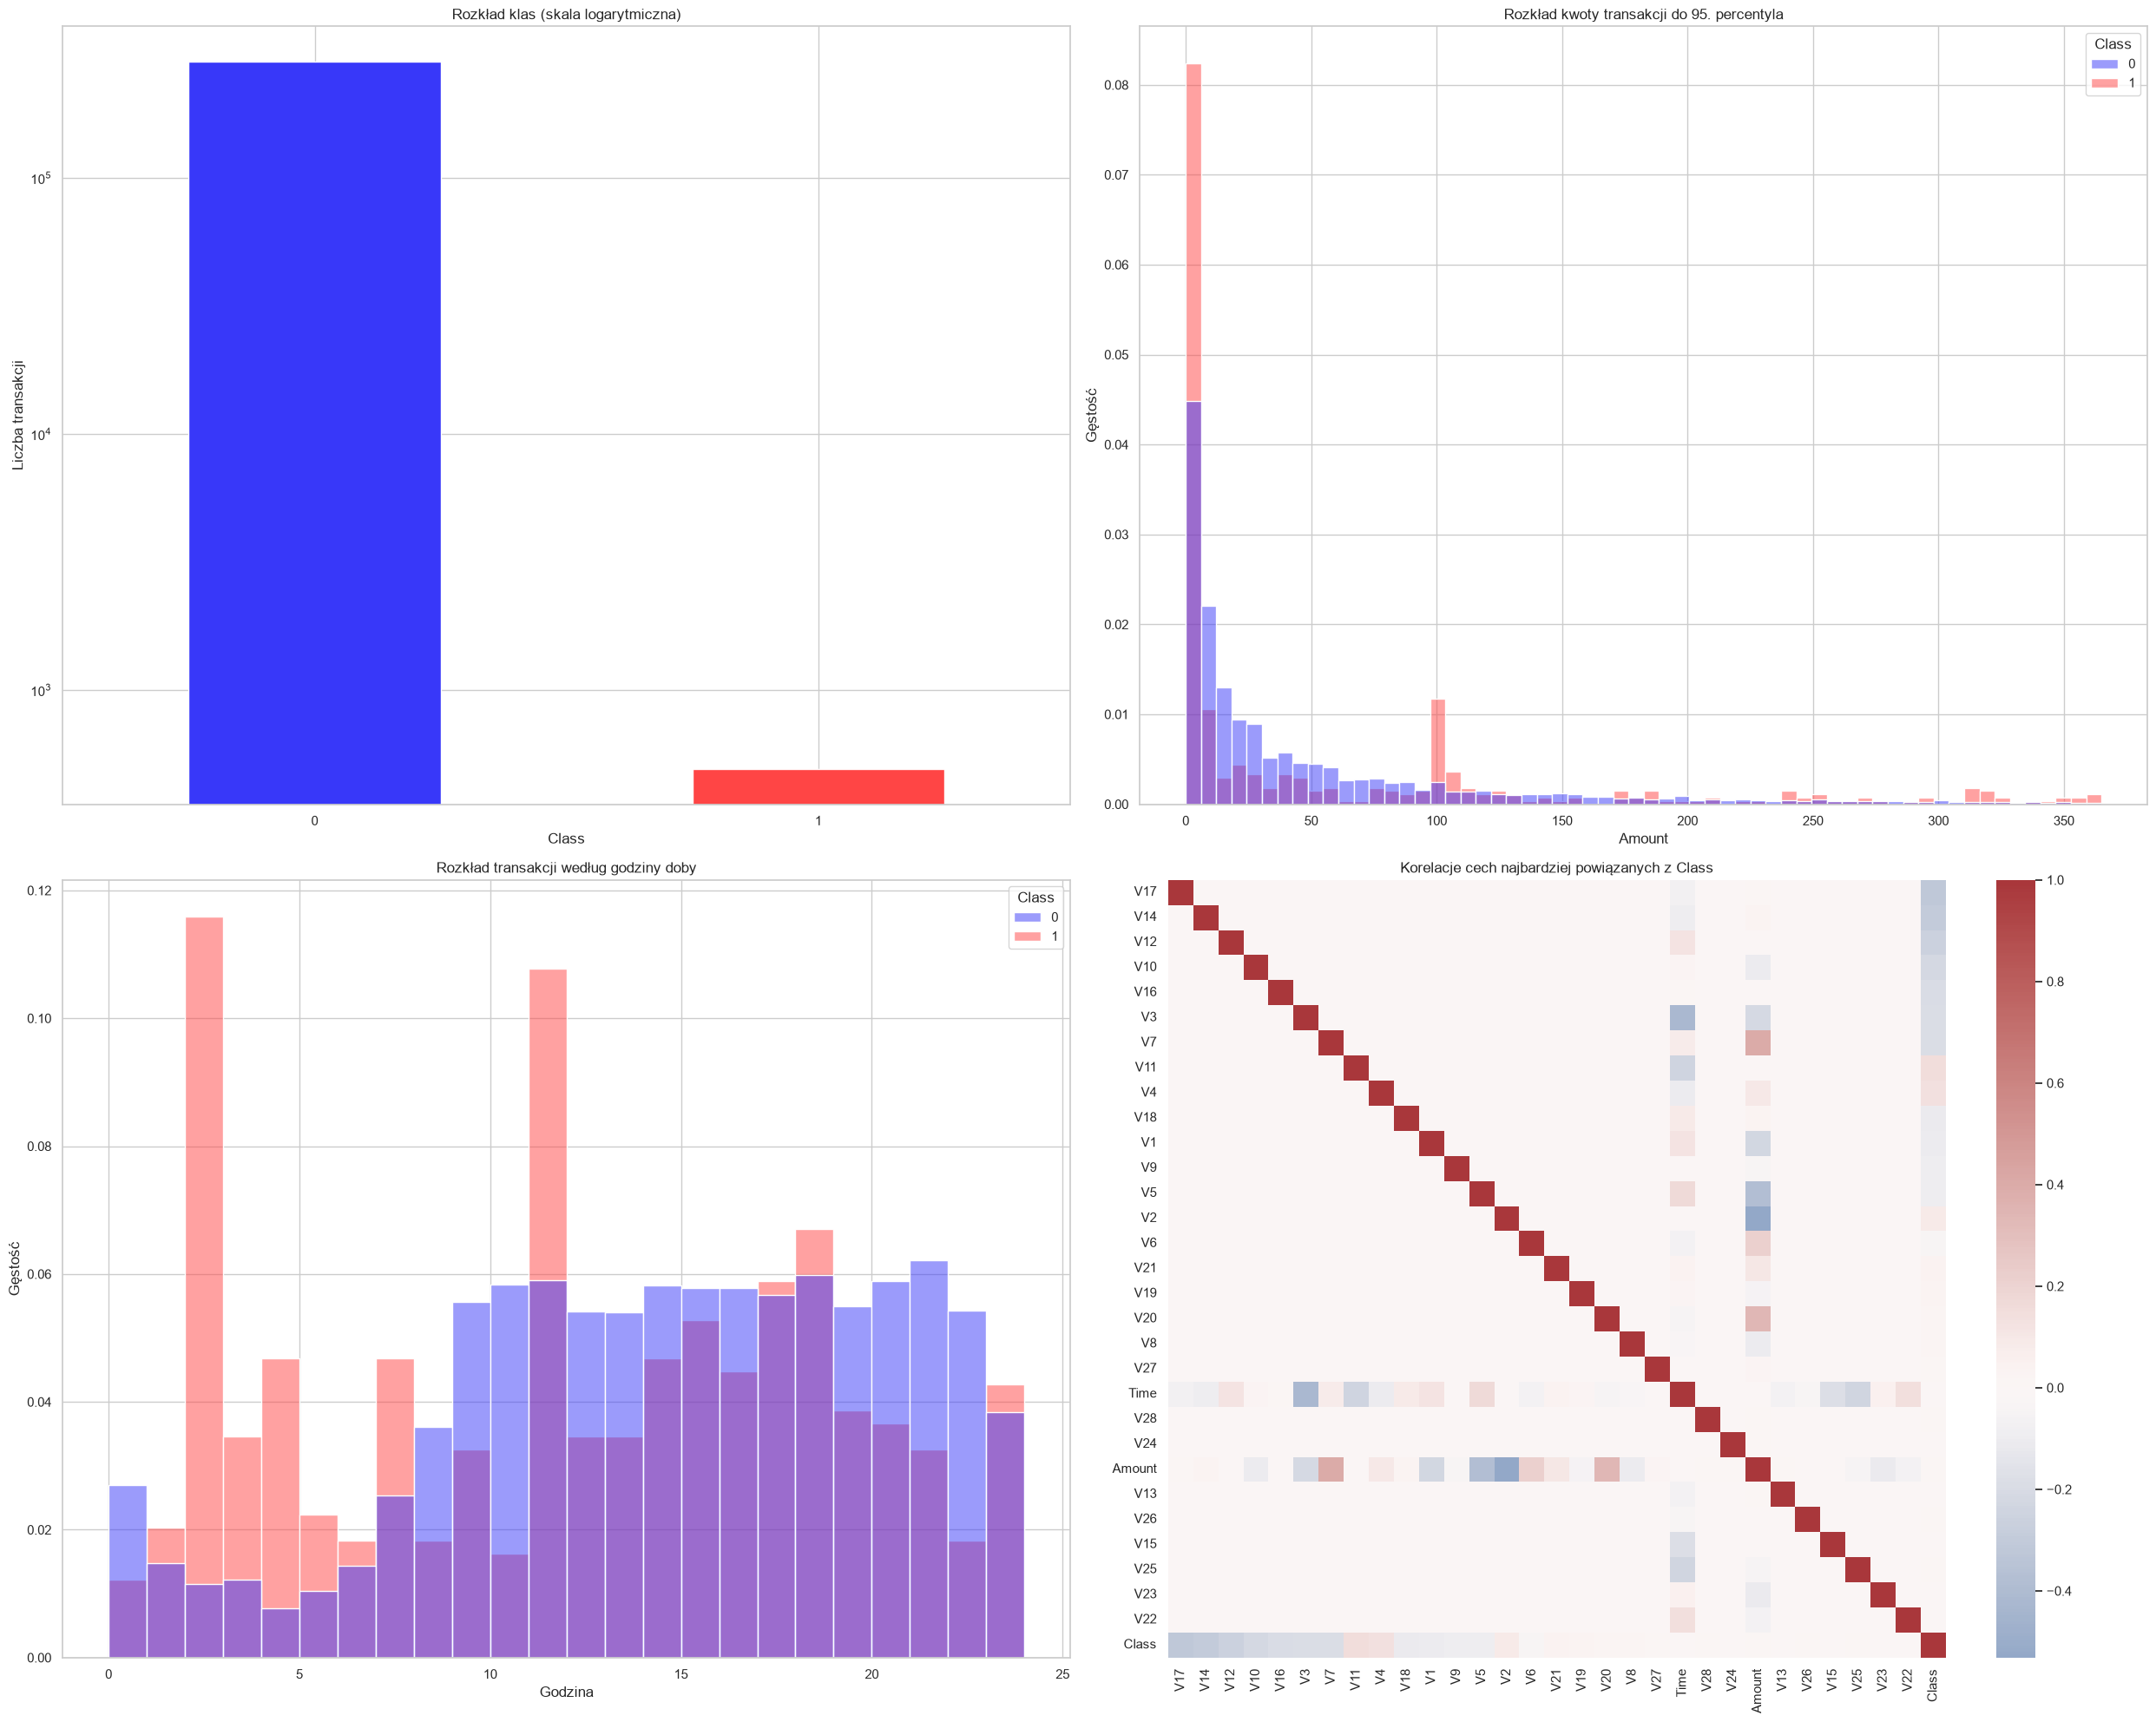

In [119]:
class_palette = {0: "#3838F9", 1: "#FF4545"}
fig, axes = plt.subplots(2, 2, figsize=(25, 20))

class_counts.plot(kind="bar", color=[class_palette[0], class_palette[1]], ax=axes[0, 0])
axes[0, 0].set_title("Rozkład klas (skala logarytmiczna)")
axes[0, 0].set_xlabel("Class")
axes[0, 0].set_ylabel("Liczba transakcji")
axes[0, 0].set_yscale("log")
axes[0, 0].tick_params(axis="x", rotation=0)

amount_limit = df["Amount"].quantile(0.95)
amount_view = df.loc[df["Amount"] <= amount_limit, ["Amount", "Class"]]
sns.histplot(
    data=amount_view,
    x="Amount",
    hue="Class",
    bins=60,
    stat="density",
    common_norm=False,
    palette=class_palette,
    ax=axes[0, 1],
)
axes[0, 1].set_title("Rozkład kwoty transakcji do 95. percentyla")
axes[0, 1].set_xlabel("Amount")
axes[0, 1].set_ylabel("Gęstość")

time_view = pd.DataFrame({
    "Hour": (df["Time"] / 3600) % 24,
    "Class": df["Class"],
})
sns.histplot(
    data=time_view,
    x="Hour",
    hue="Class",
    bins=24,
    stat="density",
    common_norm=False,
    palette=class_palette,
    ax=axes[1, 0],
)
axes[1, 0].set_title("Rozkład transakcji według godziny doby")
axes[1, 0].set_xlabel("Godzina")
axes[1, 0].set_ylabel("Gęstość")

top_corr_features = corr_with_target.index.tolist()
sns.heatmap(
    df[top_corr_features + ["Class"]].corr(),
    cmap="vlag",
    center=0,
    annot=False,
    square=True,
    ax=axes[1, 1],
)
axes[1, 1].set_title("Korelacje cech najbardziej powiązanych z Class")

plt.tight_layout()
plt.show()


### Key EDA Findings
1. The dataset contains 284,807 observations and 31 numeric columns. `Class` is the binary target and there are no missing values.
2. Fraud accounts for only about 0.173% of records, so accuracy is not a suitable primary metric. Recall, precision, F2, PR-AUC and confusion matrices are used instead.
3. `Amount` is strongly right-skewed: the median is 22.00, the mean is 88.35 and the maximum is 25,691.16. This supports the use of outlier-robust scaling.
4. Features `V1`–`V28` are PCA-transformed. They can be used directly by numerical models, but have limited business interpretability.
5. The dataset contains 1,081 exact duplicate rows. They are retained because repeated records can represent real financial transactions.
6. `Time` spans about 48 hours and may contain useful transaction-rhythm information.

## 2. Data Splitting


In [120]:
TARGET = "Class"
TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15

X = df.drop(columns=TARGET)
y = df[TARGET].astype(int)

X_train_and_validate_raw, X_test_raw, y_train_and_validate, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_train_raw, X_validate_raw, y_train, y_validate = train_test_split(
    X_train_and_validate_raw,
    y_train_and_validate,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_train_and_validate,
)

split_summary = pd.DataFrame({
    "zbiór": ["train_model", "validate", "test"],
    "liczba wierszy": [len(X_train_raw), len(X_validate_raw), len(X_test_raw)],
    "udział zbioru %": [
        len(X_train_raw) / len(df) * 100,
        len(X_validate_raw) / len(df) * 100,
        len(X_test_raw) / len(df) * 100,
    ],
    "legalne": [(y_train == 0).sum(), (y_validate == 0).sum(), (y_test == 0).sum()],
    "fraud": [(y_train == 1).sum(), (y_validate == 1).sum(), (y_test == 1).sum()],
    "udział fraud %": [y_train.mean() * 100, y_validate.mean() * 100, y_test.mean() * 100],
})

display(split_summary)
print(f"Pełny zbiór treningowy przed wydzieleniem validation: {X_train_and_validate_raw.shape[0]:,} wierszy")
print(f"Liczba cech wejściowych: {X_train_and_validate_raw.shape[1]}")
print(
    "Indeksy train_model/validate/test są rozłączne: "
    f"{set(X_train_raw.index).isdisjoint(set(X_validate_raw.index)) and set(X_validate_raw.index).isdisjoint(set(X_test_raw.index)) and set(X_train_raw.index).isdisjoint(set(X_test_raw.index))}"
)


,zbiór,liczba wierszy,udział zbioru %,legalne,fraud,udział fraud %
0,train_model,205772,72.2496,205417,355,0.1725
1,validate,36313,12.7500,36250,63,0.1735
2,test,42722,15.0003,42648,74,0.1732


Pełny zbiór treningowy przed wydzieleniem validation: 242,085 wierszy
Liczba cech wejściowych: 30
Indeksy train_model/validate/test są rozłączne: True


### Split Design

The hold-out test set is separated before fitting any learned transformation. The remaining data is split into training and validation sets for model and threshold selection. This prevents the scaler, SMOTE procedure and model-selection process from seeing test-set information.

Data leakage would occur if scaling or oversampling were fitted on the full dataset before the split, or if the test set were used to choose hyperparameters or a decision threshold. Raw train, validation and test splits are retained separately to avoid this.

Stratification keeps the very rare fraud class at a comparable proportion in the train, validation and test sets.

## 3. Feature Engineering and Scaling


In [121]:
SECONDS_IN_DAY = 24 * 60 * 60
TIME_FEATURES = ["SecondsOfDay", "Hour_sin", "Hour_cos"]
SCALE_COLUMNS = ["Amount", "Time"]


def add_time_attributes(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()
    seconds_of_day = data["Time"] % SECONDS_IN_DAY

    data["SecondsOfDay"] = seconds_of_day
    data["Hour_sin"] = np.sin(2 * np.pi * seconds_of_day / SECONDS_IN_DAY)
    data["Hour_cos"] = np.cos(2 * np.pi * seconds_of_day / SECONDS_IN_DAY)
    return data


print(f"Liczba cech przed transformacją: {X_train_raw.shape[1]}")

X_train = add_time_attributes(X_train_raw)
X_validate = add_time_attributes(X_validate_raw)
X_test = add_time_attributes(X_test_raw)

print(f"Liczba cech po dodaniu atrybutów czasu: {X_train.shape[1]}")
print("Nowe cechy czasu: SecondsOfDay, Hour_sin, Hour_cos")

robust_scaler = RobustScaler()

X_train[SCALE_COLUMNS] = robust_scaler.fit_transform(X_train[SCALE_COLUMNS])
X_validate[SCALE_COLUMNS] = robust_scaler.transform(X_validate[SCALE_COLUMNS])
X_test[SCALE_COLUMNS] = robust_scaler.transform(X_test[SCALE_COLUMNS])


Liczba cech przed transformacją: 30
Liczba cech po dodaniu atrybutów czasu: 33
Nowe cechy czasu: SecondsOfDay, Hour_sin, Hour_cos


`SecondsOfDay`, `Hour_sin` and `Hour_cos` are added because transaction time is cyclical within a day. The sine/cosine pair allows the model to treat times near midnight as close together.

### Transformation Rationale

`RobustScaler` is applied to `Amount` and `Time` because they have a different scale from the PCA features and are sensitive to outliers. Alternatives such as `StandardScaler`, `log1p` or no scaling were considered; robust scaling is the safer choice for a strongly skewed amount distribution.

The scaler is fitted only on the training data. Validation and test data are transformed with the same fitted scaler, without refitting.

# Model Development


### Shared Evaluation Utilities

In [122]:
def metrics_report(model_name, y_true, y_pred, y_score=None, beta=2, threshold=None):
    """Zwraca jednowierszową tabelę najważniejszych metryk klasyfikacji."""
    metrics = {
        "model": [model_name],
    }
    if threshold is not None:
        metrics["threshold"] = [threshold]

    metrics.update({
        "precision": [precision_score(y_true, y_pred, zero_division=0)],
        "recall": [recall_score(y_true, y_pred, zero_division=0)],
        "f1": [f1_score(y_true, y_pred, zero_division=0)],
        "f2": [fbeta_score(y_true, y_pred, beta=beta, zero_division=0)],
    })

    if y_score is not None:
        y_score = np.asarray(y_score)
        if y_score.ndim == 2:
            y_score = y_score[:, 1]

        try:
            metrics["pr_auc"] = [average_precision_score(y_true, y_score)]
        except ValueError:
            metrics["pr_auc"] = [np.nan]
        try:
            metrics["roc_auc"] = [roc_auc_score(y_true, y_score)]
        except ValueError:
            metrics["roc_auc"] = [np.nan]

    return pd.DataFrame(metrics)


In [123]:
def best_f2_threshold(y_true, y_score, beta=2):
    """Zwraca próg decyzyjny z najwyższym F-beta."""
    precision, recall, thresholds = precision_recall_curve(y_true, y_score)

    threshold_table = pd.DataFrame({
        "threshold": thresholds,
        "precision": precision[:-1],
        "recall": recall[:-1],
    })

    beta_squared = beta ** 2
    threshold_table["f2"] = (
        (1 + beta_squared) * threshold_table["precision"] * threshold_table["recall"]
        / (beta_squared * threshold_table["precision"] + threshold_table["recall"])
    ).replace([np.inf, -np.inf], 0).fillna(0)

    best_row = threshold_table.loc[threshold_table["f2"].idxmax()]
    return float(best_row["threshold"])


### Model Factory Functions


In [124]:
def create_rf_smote_pipeline(random_state=RANDOM_STATE, smote_params=None, rf_params=None):
    """Tworzy pipeline SMOTE + Random Forest."""
    smote_config = {"random_state": random_state}
    smote_config.update(smote_params or {})

    rf_config = {"random_state": random_state, "n_jobs": -1}
    rf_config.update(rf_params or {})

    return ImbPipeline(steps=[
        ("smote", SMOTE(**smote_config)),
        ("random_forest", RandomForestClassifier(**rf_config)),
    ])


def create_isolation_forest_model(random_state=RANDOM_STATE, contamination="auto", iforest_params=None):
    """Tworzy model Isolation Forest."""
    iforest_config = {
        "random_state": random_state,
        "contamination": contamination,
        "n_jobs": -1,
    }
    iforest_config.update(iforest_params or {})
    return IsolationForest(**iforest_config)


def create_xgboost_model(random_state=RANDOM_STATE, xgb_params=None):
    """Tworzy klasyfikator XGBoost dla problemu binarnego."""
    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    xgb_config = {
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "tree_method": "hist",
        "random_state": random_state,
        "n_jobs": -1,
        "scale_pos_weight": scale_pos_weight,
    }
    xgb_config.update(xgb_params or {})
    return XGBClassifier(**xgb_config)

## Random Forest + SMOTE

In [125]:
# Random Forest + SMOTE – inicjalizacja, hiperparametry, trenowanie

rf_smote_pipeline = create_rf_smote_pipeline()
rf_smote_pipeline.fit(X_train, y_train)

rf_smote_proba = rf_smote_pipeline.predict_proba(X_validate)[:, 1]
rf_smote_threshold = best_f2_threshold(
    y_validate,
    rf_smote_proba,
    beta=2,
)
rf_smote_pred = (rf_smote_proba >= rf_smote_threshold).astype(int)


rf_smote_metrics = metrics_report(
    model_name="Random Forest + SMOTE (default)",
    y_true=y_validate,
    y_pred=rf_smote_pred,
    y_score=rf_smote_proba,
    beta=2,
    threshold=rf_smote_threshold,
)

display(rf_smote_metrics.round(4))



,model,threshold,precision,recall,f1,f2,pr_auc,roc_auc
0,Random Forest + SMOTE (default),0.3800,0.8871,0.8730,0.8800,0.8758,0.8523,0.9718


In [126]:
print(classification_report(y_true=y_validate, y_pred=rf_smote_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     36250
           1       0.89      0.87      0.88        63

    accuracy                           1.00     36313
   macro avg       0.94      0.94      0.94     36313
weighted avg       1.00      1.00      1.00     36313



In [127]:
rf_smote_balance_before = y_train.value_counts().sort_index()
rf_smote_balance_after = rf_smote_balance_before.copy()
for class_label, generated_count in rf_smote_pipeline.named_steps["smote"].sampling_strategy_.items():
    rf_smote_balance_after.loc[class_label] += generated_count

rf_smote_balance = pd.DataFrame({
    "przed_SMOTE": rf_smote_balance_before,
    "po_SMOTE": rf_smote_balance_after,
}).rename(index={0: "legalna", 1: "oszustwo"})

display(rf_smote_balance)

,przed_SMOTE,po_SMOTE
Class,,
legalna,205417,205417
oszustwo,355,205417


### Model Notes

**Random Forest** combines independent decision trees trained on random samples and feature subsets. It models nonlinear relationships and interactions without assuming linearity. **SMOTE** creates synthetic minority-class observations from nearest neighbours.

This approach can be weaker when synthetic fraud examples are unrealistic or the classes overlap substantially. On a rare positive class, recall, precision, F1/F2 and PR-AUC are more informative than accuracy.

## Isolation Forest


In [128]:
# Isolation Forest – inicjalizacja, hiperparametry, trenowanie

X_train_legal = X_train.loc[y_train == 0]

iforest_model = create_isolation_forest_model(
    contamination=y_train.mean(),
)
iforest_model.fit(X_train_legal)

iforest_score = -iforest_model.decision_function(X_validate)
iforest_threshold = best_f2_threshold(
    y_validate,
    iforest_score,
    beta=2,
)
iforest_pred = (iforest_score >= iforest_threshold).astype(int)

iforest_train_summary = pd.DataFrame({
    "zbiór": ["train_all", "train_legal_used_by_iforest"],
    "liczba_wierszy": [len(X_train), len(X_train_legal)],
    "fraud": [(y_train == 1).sum(), 0],
})

iforest_metrics = metrics_report(
    model_name="Isolation Forest",
    y_true=y_validate,
    y_pred=iforest_pred,
    y_score=iforest_score,
    beta=2,
    threshold=iforest_threshold,
)

display(iforest_train_summary)
display(iforest_metrics.round(4))


,zbiór,liczba_wierszy,fraud
0,train_all,205772,355
1,train_legal_used_by_iforest,205417,0


,model,threshold,precision,recall,f1,f2,pr_auc,roc_auc
0,Isolation Forest,-0.0204,0.1679,0.3651,0.2300,0.2956,0.1098,0.9398


In [129]:
print(classification_report(
    y_true=y_validate,
    y_pred=iforest_pred,
    target_names=["legalna", "oszustwo"],
    digits=4,
    zero_division=0,
))


              precision    recall  f1-score   support

     legalna     0.9989    0.9969    0.9979     36250
    oszustwo     0.1679    0.3651    0.2300        63

    accuracy                         0.9958     36313
   macro avg     0.5834    0.6810    0.6139     36313
weighted avg     0.9975    0.9958    0.9965     36313



### Model Notes

**Isolation Forest** assumes that unusual observations can be isolated with fewer random splits than typical observations. It is trained only on legitimate transactions to model normal behaviour; transactions with high anomaly scores are considered potential fraud.

It can perform poorly when fraud resembles legitimate behaviour or when legitimate transactions are themselves very diverse. Random splits may also be less effective in high-dimensional noisy data.

## XGBoost


In [130]:
# XGBoost – inicjalizacja, hiperparametry, trenowanie

xgb_model = create_xgboost_model(
    xgb_params={
        "n_estimators": 200,
        "max_depth": 4,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
    }
)
xgb_model.fit(X_train, y_train)

xgb_proba = xgb_model.predict_proba(X_validate)[:, 1]
xgb_threshold = best_f2_threshold(
    y_validate,
    xgb_proba,
    beta=2,
)
xgb_pred = (xgb_proba >= xgb_threshold).astype(int)

xgb_metrics = metrics_report(
    model_name="XGBoost",
    y_true=y_validate,
    y_pred=xgb_pred,
    y_score=xgb_proba,
    beta=2,
    threshold=xgb_threshold,
)

display(xgb_metrics.round(4))


,model,threshold,precision,recall,f1,f2,pr_auc,roc_auc
0,XGBoost,0.8092,0.7534,0.8730,0.8088,0.8462,0.8317,0.9868


In [131]:
print(classification_report(
    y_true=y_validate,
    y_pred=xgb_pred,
    target_names=["legalna", "oszustwo"],
    digits=4,
    zero_division=0,
))


              precision    recall  f1-score   support

     legalna     0.9998    0.9995    0.9996     36250
    oszustwo     0.7534    0.8730    0.8088        63

    accuracy                         0.9993     36313
   macro avg     0.8766    0.9363    0.9042     36313
weighted avg     0.9994    0.9993    0.9993     36313



### Model Notes

**XGBoost** sequentially adds weak trees that correct errors made by earlier trees. It captures nonlinearities and feature interactions. `scale_pos_weight` addresses class imbalance without creating synthetic observations.

Overly deep trees or an aggressive learning rate can cause overfitting. The default 0.5 decision threshold may also be unsuitable when F2 is the main objective.

## Hyperparameter Analysis

Each model family is evaluated with three manually selected configurations to examine the effects of model complexity, regularisation and class-imbalance handling.


In [132]:
# Random Forest + SMOTE – 3 ręczne konfiguracje hiperparametrów

rf_manual_configs = [
    {
        "name": "rf_smote_deep_full",
        "rf_params": {
            "n_estimators": 200,
            "max_depth": None,
            "min_samples_leaf": 1,
            "max_features": "sqrt",
        },
        "smote_params": {
            "sampling_strategy": 1.0,
            "k_neighbors": 5,
        },
    },
    {
        "name": "rf_smote_balanced_075",
        "rf_params": {
            "n_estimators": 200,
            "max_depth": 20,
            "min_samples_leaf": 2,
            "min_samples_split": 5,
            "max_features": "sqrt",
        },
        "smote_params": {
            "sampling_strategy": 0.75,
            "k_neighbors": 5,
        },
    },
    {
        "name": "rf_smote_regularized_050",
        "rf_params": {
            "n_estimators": 300,
            "max_depth": 12,
            "min_samples_leaf": 5,
            "min_samples_split": 10,
            "max_features": "sqrt",
        },
        "smote_params": {
            "sampling_strategy": 0.5,
            "k_neighbors": 3,
        },
    },
]


In [133]:
rf_manual_result_rows = []
rf_manual_outputs = {}

for config in rf_manual_configs:
    model_name = config["name"]
    rf_params = config["rf_params"]
    smote_params = config["smote_params"]

    pipeline = create_rf_smote_pipeline(
        rf_params=rf_params,
        smote_params=smote_params,
    )
    pipeline.fit(X_train, y_train)

    y_proba = pipeline.predict_proba(X_validate)[:, 1]
    threshold = best_f2_threshold(y_validate, y_proba, beta=2)
    y_pred = (y_proba >= threshold).astype(int)

    result_row = metrics_report(
        model_name=model_name,
        y_true=y_validate,
        y_pred=y_pred,
        y_score=y_proba,
        beta=2,
        threshold=threshold,
    ).iloc[0].to_dict()
    result_row["config"] = model_name
    result_row["rf_params"] = str(rf_params)
    result_row["smote_params"] = str(smote_params)
    rf_manual_result_rows.append(result_row)

    rf_manual_outputs[model_name] = {
        "pipeline": pipeline,
        "threshold": threshold,
        "y_pred": y_pred,
        "y_proba": y_proba,
    }

rf_manual_results = (
    pd.DataFrame(rf_manual_result_rows)
    .sort_values("f2", ascending=False)
    .reset_index(drop=True)
)
rf_manual_best_config = rf_manual_results.iloc[0]

display_columns = [
    "config", "threshold", "precision", "recall",
    "f1", "f2", "pr_auc", "roc_auc",
    "rf_params", "smote_params",
]
display(rf_manual_results[display_columns].round(4))


,config,threshold,precision,recall,f1,f2,pr_auc,roc_auc,rf_params,smote_params
0,rf_smote_regularized_050,0.4345,0.8235,0.8889,0.8550,0.8750,0.8618,0.9838,"{'n_estimators': 300, 'max_depth': 12, 'min_sa...","{'sampling_strategy': 0.5, 'k_neighbors': 3}"
1,rf_smote_deep_full,0.2600,0.7887,0.8889,0.8358,0.8669,0.8674,0.9707,"{'n_estimators': 200, 'max_depth': None, 'min_...","{'sampling_strategy': 1.0, 'k_neighbors': 5}"
2,rf_smote_balanced_075,0.2958,0.7887,0.8889,0.8358,0.8669,0.8658,0.9852,"{'n_estimators': 200, 'max_depth': 20, 'min_sa...","{'sampling_strategy': 0.75, 'k_neighbors': 5}"


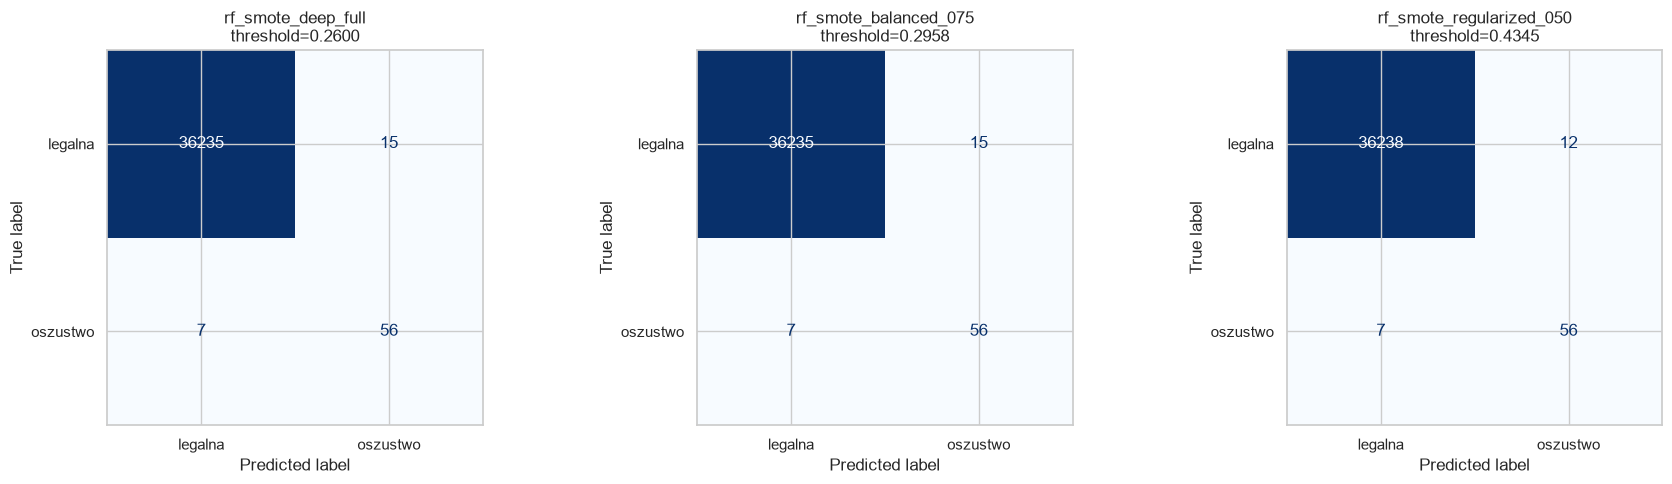

In [134]:
# Macierze pomyłek – konfiguracje Random Forest + SMOTE

fig, axes = plt.subplots(1, len(rf_manual_outputs), figsize=(6 * len(rf_manual_outputs), 5))
axes = np.atleast_1d(axes)

for ax, (model_name, output) in zip(axes, rf_manual_outputs.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_validate,
        output["y_pred"],
        display_labels=["legalna", "oszustwo"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(chr(10).join([
        model_name,
        f"threshold={output['threshold']:.4f}",
    ]))

plt.tight_layout()

### Random Forest + SMOTE Findings

Tree-complexity controls (`max_depth`, `min_samples_leaf` and `min_samples_split`) and SMOTE's `sampling_strategy` have the largest effect. `rf_smote_regularized_050` performs best: shallower trees and less oversampling (`sampling_strategy=0.5`) improve precision while retaining high recall.

All three configurations achieve the same recall (`0.8889`) and a narrow F2 range (`0.8669`–`0.8750`), indicating reasonably stable behaviour.


In [135]:
# Isolation Forest – 3 ręczne konfiguracje hiperparametrów

iforest_manual_configs = [
    {
        "name": "iforest_baseline",
        "contamination": y_train.mean(),
        "params": {
            "n_estimators": 100,
            "max_samples": "auto",
            "max_features": 1.0,
        },
    },
    {
        "name": "iforest_more_trees_local",
        "contamination": y_train.mean(),
        "params": {
            "n_estimators": 200,
            "max_samples": 1024,
            "max_features": 0.7,
        },
    },
    {
        "name": "iforest_more_trees_global",
        "contamination": y_train.mean(),
        "params": {
            "n_estimators": 200,
            "max_samples": 4096,
            "max_features": 1.0,
        },
    },
]


In [136]:
X_train_legal = X_train.loc[y_train == 0]

iforest_manual_result_rows = []
iforest_manual_outputs = {}

for config in iforest_manual_configs:
    model_name = config["name"]
    contamination = config["contamination"]
    iforest_params = config["params"]

    model = create_isolation_forest_model(
        contamination=contamination,
        iforest_params=iforest_params,
    )
    model.fit(X_train_legal)

    score = -model.decision_function(X_validate)
    threshold = best_f2_threshold(y_validate, score, beta=2)
    y_pred = (score >= threshold).astype(int)

    result_row = metrics_report(
        model_name=model_name,
        y_true=y_validate,
        y_pred=y_pred,
        y_score=score,
        beta=2,
        threshold=threshold,
    ).iloc[0].to_dict()
    result_row["config"] = model_name
    result_row["contamination"] = contamination
    result_row["iforest_params"] = str(iforest_params)
    iforest_manual_result_rows.append(result_row)

    iforest_manual_outputs[model_name] = {
        "model": model,
        "threshold": threshold,
        "y_pred": y_pred,
        "score": score,
    }

iforest_manual_results = (
    pd.DataFrame(iforest_manual_result_rows)
    .sort_values("f2", ascending=False)
    .reset_index(drop=True)
)
iforest_manual_best_config = iforest_manual_results.iloc[0]

display_columns = [
    "config", "threshold", "precision", "recall",
    "f1", "f2", "pr_auc", "roc_auc",
    "contamination", "iforest_params",
]
display(iforest_manual_results[display_columns].round(4))


,config,threshold,precision,recall,f1,f2,pr_auc,roc_auc,contamination,iforest_params
0,iforest_more_trees_global,-0.0695,0.1512,0.6190,0.2430,0.3824,0.1834,0.9453,0.0017,"{'n_estimators': 200, 'max_samples': 4096, 'ma..."
1,iforest_more_trees_local,-0.0118,0.2500,0.3651,0.2968,0.3343,0.1616,0.9420,0.0017,"{'n_estimators': 200, 'max_samples': 1024, 'ma..."
2,iforest_baseline,-0.0204,0.1679,0.3651,0.2300,0.2956,0.1098,0.9398,0.0017,"{'n_estimators': 100, 'max_samples': 'auto', '..."


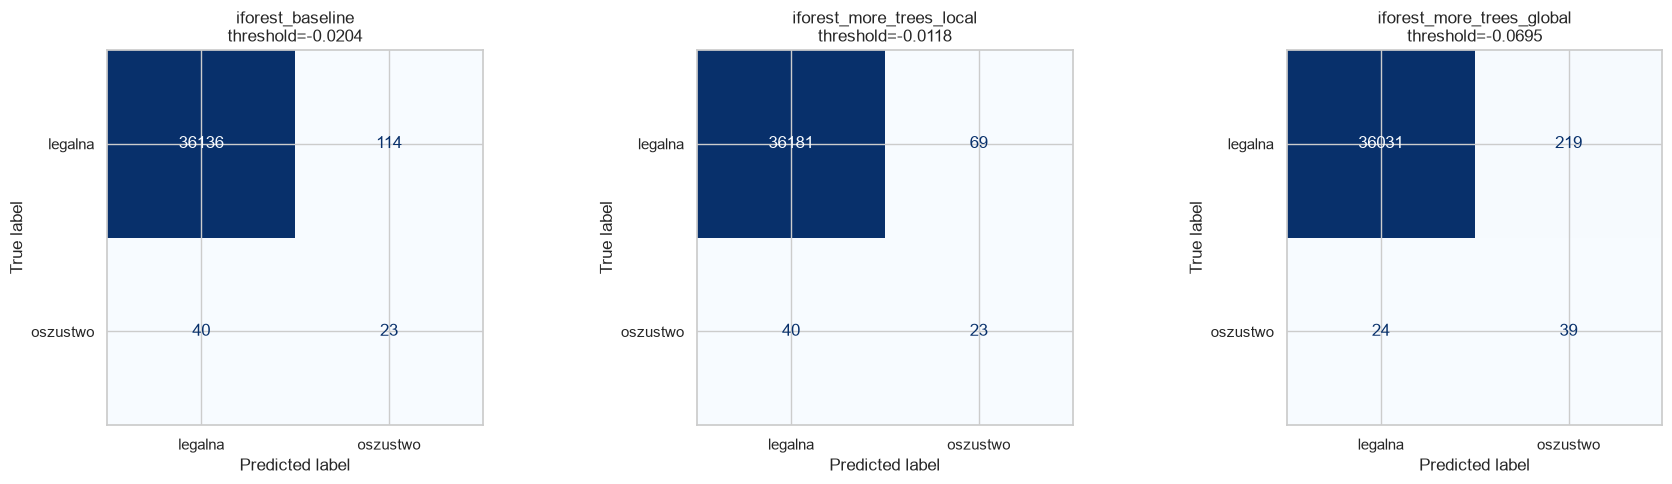

In [137]:
# Macierze pomyłek – konfiguracje Isolation Forest

fig, axes = plt.subplots(1, len(iforest_manual_outputs), figsize=(6 * len(iforest_manual_outputs), 5))
axes = np.atleast_1d(axes)

for ax, (model_name, output) in zip(axes, iforest_manual_outputs.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_validate,
        output["y_pred"],
        display_labels=["legalna", "oszustwo"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(chr(10).join([
        model_name,
        f"threshold={output['threshold']:.4f}",
    ]))

plt.tight_layout()

### Isolation Forest Findings

`max_samples` and `max_features` have the largest impact because they determine the samples and features used to isolate unusual observations. `iforest_more_trees_global`, with a larger sample (`max_samples=4096`) and all features, performs best.

The model is less stable: F2 ranges from `0.2956` to `0.3824` and recall from `0.3651` to `0.6190`. Precision remains low, producing many false alarms.


In [138]:
# XGBoost – 3 ręczne konfiguracje hiperparametrów

xgb_manual_configs = [
    {
        "name": "xgb_weighted_base",
        "params": {
            "n_estimators": 200,
            "max_depth": 4,
            "learning_rate": 0.05,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
            "min_child_weight": 1,
            "reg_lambda": 1.0,
        },
    },
    {
        "name": "xgb_regularized_shallow",
        "params": {
            "n_estimators": 300,
            "max_depth": 3,
            "learning_rate": 0.03,
            "subsample": 0.9,
            "colsample_bytree": 0.9,
            "min_child_weight": 5,
            "gamma": 1.0,
            "reg_lambda": 2.0,
        },
    },
    {
        "name": "xgb_deeper_checked",
        "params": {
            "n_estimators": 250,
            "max_depth": 5,
            "learning_rate": 0.04,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
            "min_child_weight": 2,
            "gamma": 0.5,
            "reg_lambda": 1.5,
        },
    },
]

In [139]:
xgb_manual_result_rows = []
xgb_manual_outputs = {}

for config in xgb_manual_configs:
    model_name = config["name"]
    xgb_params = config["params"]

    model = create_xgboost_model(xgb_params=xgb_params)
    model.fit(X_train, y_train)

    y_proba = model.predict_proba(X_validate)[:, 1]
    threshold = best_f2_threshold(y_validate, y_proba, beta=2)
    y_pred = (y_proba >= threshold).astype(int)

    result_row = metrics_report(
        model_name=model_name,
        y_true=y_validate,
        y_pred=y_pred,
        y_score=y_proba,
        beta=2,
        threshold=threshold,
    ).iloc[0].to_dict()
    result_row["config"] = model_name
    result_row["xgb_params"] = str(xgb_params)
    xgb_manual_result_rows.append(result_row)

    xgb_manual_outputs[model_name] = {
        "model": model,
        "threshold": threshold,
        "y_pred": y_pred,
        "y_proba": y_proba,
    }

xgb_manual_results = (
    pd.DataFrame(xgb_manual_result_rows)
    .sort_values("f2", ascending=False)
    .reset_index(drop=True)
)
xgb_manual_best_config = xgb_manual_results.iloc[0]

display_columns = [
    "config", "threshold", "precision", "recall",
    "f1", "f2", "pr_auc", "roc_auc", "xgb_params",
]
display(xgb_manual_results[display_columns].round(4))

,config,threshold,precision,recall,f1,f2,pr_auc,roc_auc,xgb_params
0,xgb_weighted_base,0.8092,0.7534,0.8730,0.8088,0.8462,0.8317,0.9868,"{'n_estimators': 200, 'max_depth': 4, 'learnin..."
1,xgb_deeper_checked,0.5487,0.7089,0.8889,0.7887,0.8459,0.8469,0.9877,"{'n_estimators': 250, 'max_depth': 5, 'learnin..."
2,xgb_regularized_shallow,0.9401,0.7237,0.8730,0.7914,0.8384,0.7671,0.9891,"{'n_estimators': 300, 'max_depth': 3, 'learnin..."


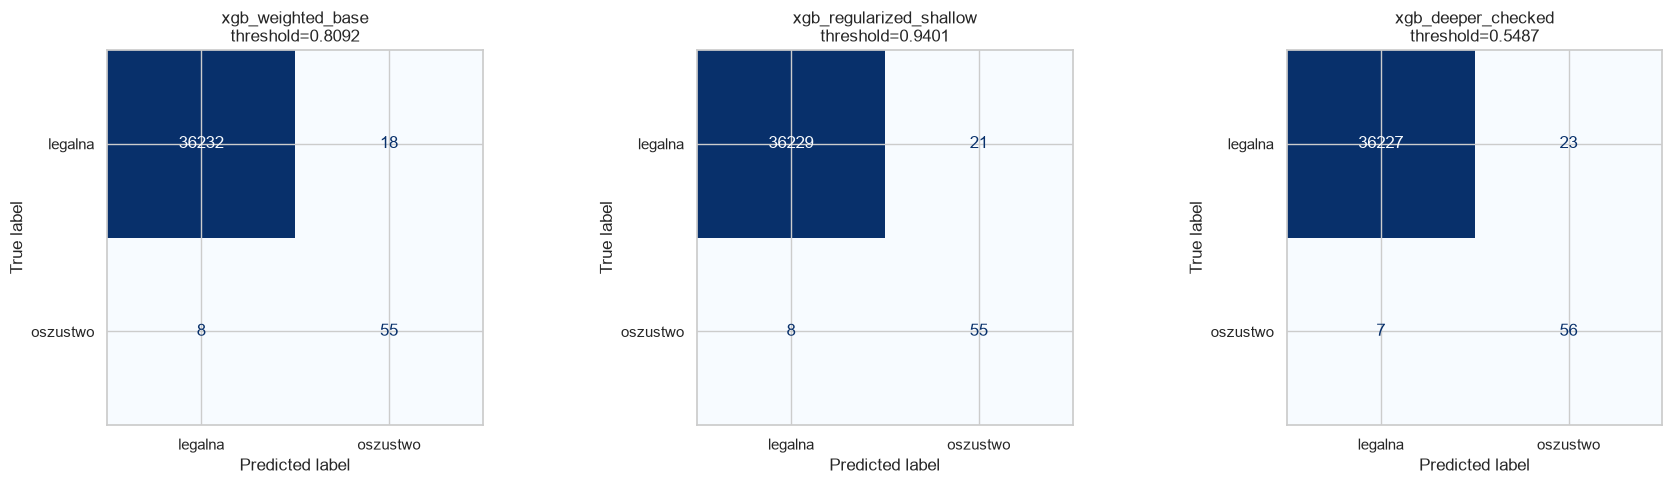

In [140]:
# Macierze pomyłek – konfiguracje XGBoost

fig, axes = plt.subplots(1, len(xgb_manual_outputs), figsize=(6 * len(xgb_manual_outputs), 5))
axes = np.atleast_1d(axes)

for ax, (model_name, output) in zip(axes, xgb_manual_outputs.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_validate,
        output["y_pred"],
        display_labels=["legalna", "oszustwo"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(chr(10).join([
        model_name,
        f"threshold={output['threshold']:.4f}",
    ]))

plt.tight_layout()

### XGBoost Findings

The largest effects come from complexity and regularisation parameters: `max_depth`, `learning_rate` and `min_child_weight`. `xgb_weighted_base`, using moderately deep trees (`max_depth=4`) and `learning_rate=0.05`, has the best F2 in this family.

XGBoost is stable, though slightly less so than Random Forest + SMOTE. All configurations have high ROC-AUC and F2 ranges only from `0.8384` to `0.8462`, while precision and recall vary more.


# Model Comparison and Selection


## Configuration Comparison

In [141]:
comparison_columns = [
    "category", "model", "threshold", "precision", "recall",
    "f1", "f2", "pr_auc", "roc_auc",
]

model_result_tables = [
    rf_manual_results.assign(
        category="Random Forest + SMOTE",
        model=rf_manual_results["config"],
    ),
    iforest_manual_results.assign(
        category="Isolation Forest",
        model=iforest_manual_results["config"],
    ),
    xgb_manual_results.assign(
        category="XGBoost",
        model=xgb_manual_results["config"],
    ),
]

all_model_results = (
    pd.concat(model_result_tables, ignore_index=True)
    .sort_values("f2", ascending=False)
    .reset_index(drop=True)
)

display(all_model_results[comparison_columns].round(4))

best_models_by_category = (
    all_model_results
    .groupby("category", as_index=False)
    .first()
    .sort_values("f2", ascending=False)
    .reset_index(drop=True)
)

print("Najlepszy model według F2 w każdej kategorii:")
display(best_models_by_category[comparison_columns].round(4))

best_overall_model = all_model_results.iloc[0]
print(
    "Najlepszy model ogólnie według F2: "
    f"{best_overall_model['model']} "
    f"({best_overall_model['category']}), "
    f"F2={best_overall_model['f2']:.4f}"
)

,category,model,threshold,precision,recall,f1,f2,pr_auc,roc_auc
0,Random Forest + SMOTE,rf_smote_regularized_050,0.4345,0.8235,0.8889,0.8550,0.8750,0.8618,0.9838
1,Random Forest + SMOTE,rf_smote_deep_full,0.2600,0.7887,0.8889,0.8358,0.8669,0.8674,0.9707
2,Random Forest + SMOTE,rf_smote_balanced_075,0.2958,0.7887,0.8889,0.8358,0.8669,0.8658,0.9852
3,XGBoost,xgb_weighted_base,0.8092,0.7534,0.8730,0.8088,0.8462,0.8317,0.9868
4,XGBoost,xgb_deeper_checked,0.5487,0.7089,0.8889,0.7887,0.8459,0.8469,0.9877
5,XGBoost,xgb_regularized_shallow,0.9401,0.7237,0.8730,0.7914,0.8384,0.7671,0.9891
6,Isolation Forest,iforest_more_trees_global,-0.0695,0.1512,0.6190,0.2430,0.3824,0.1834,0.9453
7,Isolation Forest,iforest_more_trees_local,-0.0118,0.2500,0.3651,0.2968,0.3343,0.1616,0.9420
8,Isolation Forest,iforest_baseline,-0.0204,0.1679,0.3651,0.2300,0.2956,0.1098,0.9398


Najlepszy model według F2 w każdej kategorii:


,category,model,threshold,precision,recall,f1,f2,pr_auc,roc_auc
0,Random Forest + SMOTE,rf_smote_regularized_050,0.4345,0.8235,0.8889,0.8550,0.8750,0.8618,0.9838
1,XGBoost,xgb_weighted_base,0.8092,0.7534,0.8730,0.8088,0.8462,0.8317,0.9868
2,Isolation Forest,iforest_more_trees_global,-0.0695,0.1512,0.6190,0.2430,0.3824,0.1834,0.9453


Najlepszy model ogólnie według F2: rf_smote_regularized_050 (Random Forest + SMOTE), F2=0.8750


## PR and ROC Curves for the Best Models

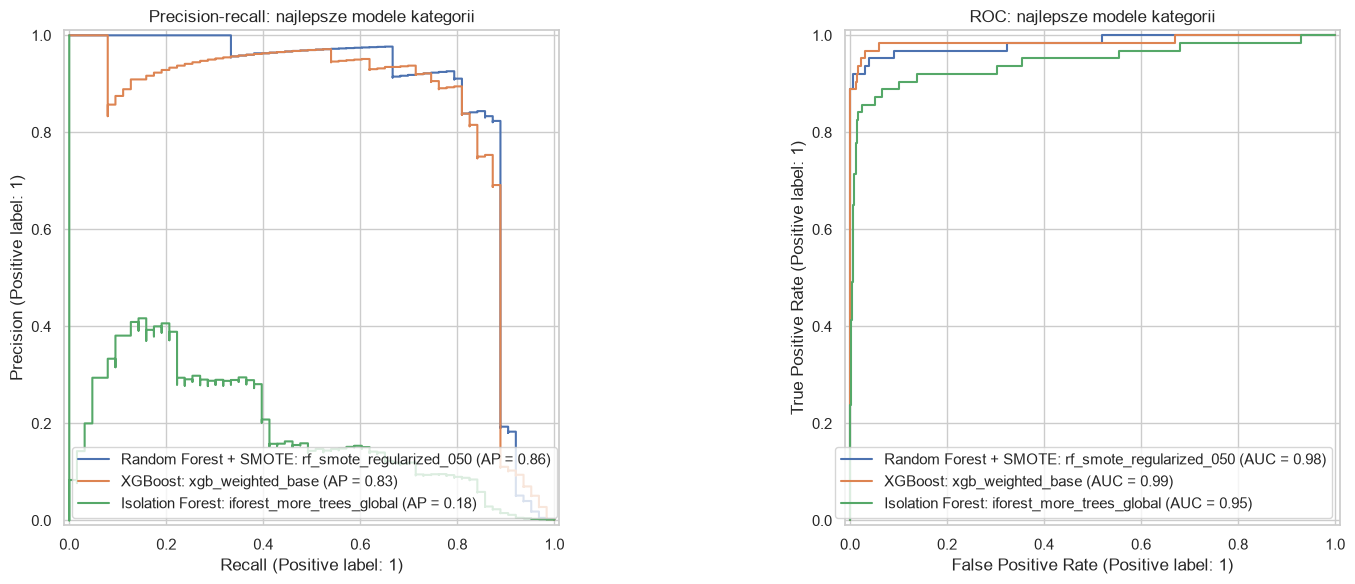

In [142]:
score_sources = {
    "Random Forest + SMOTE": (rf_manual_outputs, "y_proba"),
    "Isolation Forest": (iforest_manual_outputs, "score"),
    "XGBoost": (xgb_manual_outputs, "y_proba"),
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for _, row in best_models_by_category.iterrows():
    model_name = row["model"]
    outputs, score_key = score_sources[row["category"]]
    y_score = outputs[model_name][score_key]
    curve_label = f"{row['category']}: {model_name}"

    PrecisionRecallDisplay.from_predictions(
        y_validate,
        y_score,
        name=curve_label,
        ax=axes[0],
    )
    RocCurveDisplay.from_predictions(
        y_validate,
        y_score,
        name=curve_label,
        ax=axes[1],
    )

axes[0].set_title("Precision-recall: najlepsze modele kategorii")
axes[1].set_title("ROC: najlepsze modele kategorii")
plt.tight_layout()

### Selection Rationale

`rf_smote_regularized_050` achieves the strongest validation F2 with high recall and good precision. This fits the fraud-detection objective, where detecting as many frauds as possible matters more than maximising accuracy.

The choice is based on one validation split and its selected threshold, so results may partly depend on that split. The selected candidates are therefore examined again with cross-validation.


# Validation and Final Analysis


## Selected Models for Cross-Validation

In [143]:
def get_config(configs, model_name):
    return next(config for config in configs if config["name"] == model_name)


best_rf_name = best_models_by_category.loc[
    best_models_by_category["category"] == "Random Forest + SMOTE",
    "model",
].iloc[0]
best_iforest_name = best_models_by_category.loc[
    best_models_by_category["category"] == "Isolation Forest",
    "model",
].iloc[0]
best_xgb_name = best_models_by_category.loc[
    best_models_by_category["category"] == "XGBoost",
    "model",
].iloc[0]

best_model_configs = [
    {
        "category": "Random Forest + SMOTE",
        "model": best_rf_name,
        "config": get_config(rf_manual_configs, best_rf_name),
    },
    {
        "category": "Isolation Forest",
        "model": best_iforest_name,
        "config": get_config(iforest_manual_configs, best_iforest_name),
    },
    {
        "category": "XGBoost",
        "model": best_xgb_name,
        "config": get_config(xgb_manual_configs, best_xgb_name),
    },
]

selected_models = pd.DataFrame([
    {
        "category": model_info["category"],
        "model": model_info["model"],
        "validation_f2": all_model_results.loc[
            all_model_results["model"] == model_info["model"],
            "f2",
        ].iloc[0],
    }
    for model_info in best_model_configs
])

display(selected_models.round(4))

,category,model,validation_f2
0,Random Forest + SMOTE,rf_smote_regularized_050,0.8750
1,Isolation Forest,iforest_more_trees_global,0.3824
2,XGBoost,xgb_weighted_base,0.8462


## 10-Fold Cross-Validation

In [144]:
def prepare_train_eval_data(X_fit_raw, X_eval_raw):
    X_fit = add_time_attributes(X_fit_raw)
    X_eval = add_time_attributes(X_eval_raw)

    scaler = RobustScaler()
    X_fit[SCALE_COLUMNS] = scaler.fit_transform(X_fit[SCALE_COLUMNS])
    X_eval[SCALE_COLUMNS] = scaler.transform(X_eval[SCALE_COLUMNS])

    return X_fit, X_eval


def fit_and_score_selected_model(model_info, X_fit, y_fit, X_eval):
    category = model_info["category"]
    config = model_info["config"]

    if category == "Random Forest + SMOTE":
        model = create_rf_smote_pipeline(
            rf_params=config["rf_params"],
            smote_params=config["smote_params"],
        )
        model.fit(X_fit, y_fit)
        y_score = model.predict_proba(X_eval)[:, 1]

    elif category == "Isolation Forest":
        model = create_isolation_forest_model(
            contamination=y_fit.mean(),
            iforest_params=config["params"],
        )
        model.fit(X_fit.loc[y_fit == 0])
        y_score = -model.decision_function(X_eval)

    elif category == "XGBoost":
        xgb_params = config["params"].copy()
        xgb_params["scale_pos_weight"] = (y_fit == 0).sum() / (y_fit == 1).sum()

        model = create_xgboost_model(xgb_params=xgb_params)
        model.fit(X_fit, y_fit)
        y_score = model.predict_proba(X_eval)[:, 1]

    else:
        raise ValueError(f"Nieznana kategoria modelu: {category}")

    return model, y_score

In [145]:
CV_SPLITS = 10
cv = StratifiedKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

cv_result_rows = []

for model_info in best_model_configs:
    for fold, (fit_idx, valid_idx) in enumerate(cv.split(X_train_raw, y_train), start=1):
        X_fold_train_raw = X_train_raw.iloc[fit_idx]
        X_fold_valid_raw = X_train_raw.iloc[valid_idx]
        y_fold_train = y_train.iloc[fit_idx]
        y_fold_valid = y_train.iloc[valid_idx]

        X_fold_train, X_fold_valid = prepare_train_eval_data(
            X_fold_train_raw,
            X_fold_valid_raw,
        )
        _, y_score = fit_and_score_selected_model(
            model_info,
            X_fold_train,
            y_fold_train,
            X_fold_valid,
        )

        threshold = best_f2_threshold(y_fold_valid, y_score, beta=2)
        y_pred = (y_score >= threshold).astype(int)

        result_row = metrics_report(
            model_name=model_info["model"],
            y_true=y_fold_valid,
            y_pred=y_pred,
            y_score=y_score,
            beta=2,
            threshold=threshold,
        ).iloc[0].to_dict()
        result_row["category"] = model_info["category"]
        result_row["model"] = model_info["model"]
        result_row["fold"] = fold
        cv_result_rows.append(result_row)

cv_results = pd.DataFrame(cv_result_rows)

display_columns = [
    "category", "model", "fold", "threshold", "precision", "recall",
    "f1", "f2", "pr_auc", "roc_auc",
]
display(cv_results[display_columns].round(4))

,category,model,fold,threshold,precision,recall,f1,f2,pr_auc,roc_auc
0,Random Forest + SMOTE,rf_smote_regularized_050,1,0.6570,0.9189,0.9444,0.9315,0.9392,0.9494,0.9951
1,Random Forest + SMOTE,rf_smote_regularized_050,2,0.7121,0.8529,0.8056,0.8286,0.8146,0.7694,0.9760
2,Random Forest + SMOTE,rf_smote_regularized_050,3,0.4656,0.8571,0.8571,0.8571,0.8571,0.8653,0.9861
3,Random Forest + SMOTE,rf_smote_regularized_050,4,0.4183,0.7647,0.7429,0.7536,0.7471,0.7434,0.9768
4,Random Forest + SMOTE,rf_smote_regularized_050,5,0.5093,0.7949,0.8857,0.8378,0.8659,0.8817,0.9966
5,Random Forest + SMOTE,rf_smote_regularized_050,6,0.6609,0.8378,0.8857,0.8611,0.8757,0.9073,0.9779
6,Random Forest + SMOTE,rf_smote_regularized_050,7,0.4339,0.8000,0.8000,0.8000,0.8000,0.7816,0.9783
7,Random Forest + SMOTE,rf_smote_regularized_050,8,0.7621,0.8571,0.8333,0.8451,0.8380,0.8585,0.9977
8,Random Forest + SMOTE,rf_smote_regularized_050,9,0.5970,0.7750,0.8611,0.8158,0.8424,0.8446,0.9860
9,Random Forest + SMOTE,rf_smote_regularized_050,10,0.5946,0.9032,0.7778,0.8358,0.8000,0.7772,0.9722


In [151]:
cv_summary = (
    cv_results
    .groupby(["category", "model"], as_index=False)
    .agg(
        f2_mean=("f2", "mean"),
        f2_std=("f2", "std"),
        pr_auc_mean=("pr_auc", "mean"),
        pr_auc_std=("pr_auc", "std"),
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        precision_mean=("precision", "mean"),
        recall_mean=("recall", "mean"),
    )
    .sort_values("f2_mean", ascending=False)
    .reset_index(drop=True)
)

display(cv_summary.round(4))

cv_best_model = cv_summary.iloc[0]
print(
    "Najlepszy model w CV według średniego F2: "
    f"{cv_best_model['model']} "
    f"({cv_best_model['category']}), "
    f"F2={cv_best_model['f2_mean']:.4f} ± {cv_best_model['f2_std']:.4f}"
)

,category,model,f2_mean,f2_std,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,precision_mean,recall_mean
0,Random Forest + SMOTE,rf_smote_regularized_050,0.8380,0.0522,0.8378,0.0674,0.9843,0.0094,0.8362,0.8394
1,XGBoost,xgb_weighted_base,0.8360,0.0485,0.8253,0.0647,0.9825,0.0095,0.8609,0.8308
2,Isolation Forest,iforest_more_trees_global,0.4125,0.0684,0.2047,0.0598,0.9543,0.0200,0.2048,0.5713


Najlepszy model w CV według średniego F2: rf_smote_regularized_050 (Random Forest + SMOTE), F2=0.8380 ± 0.0522


## Wilcoxon Signed-Rank Test

The Wilcoxon signed-rank test compares paired PR-AUC scores from the same cross-validation folds. PR-AUC is used because the dataset is highly imbalanced.

The null hypothesis states that the median difference between two models is zero. A `p-value < 0.05` is treated as evidence of a statistically significant difference.

In [153]:
from scipy.stats import wilcoxon
from itertools import combinations

models = cv_results["model"].unique()
wilcoxon_rows = []

for model_1, model_2 in combinations(models, 2):
    scores_1 = cv_results.loc[
        cv_results["model"] == model_1, "pr_auc"
    ].values

    scores_2 = cv_results.loc[
        cv_results["model"] == model_2, "pr_auc"
    ].values

    statistic, p_value = wilcoxon(scores_1, scores_2)

    wilcoxon_rows.append({
        "model_1": model_1,
        "model_2": model_2,
        "statistic": statistic,
        "p_value": p_value,
        "significant": "TAK" if p_value < 0.05 else "NIE",
    })

wilcoxon_results = pd.DataFrame(wilcoxon_rows)
display(wilcoxon_results.round(4))

,model_1,model_2,statistic,p_value,significant
0,rf_smote_regularized_050,iforest_more_trees_global,0.0000,0.0020,TAK
1,rf_smote_regularized_050,xgb_weighted_base,10.0000,0.0840,NIE
2,iforest_more_trees_global,xgb_weighted_base,0.0000,0.0020,TAK


### Wilcoxon Results
The test compares PR-AUC scores from 10-fold cross-validation. The difference between Random Forest + SMOTE and XGBoost is not statistically significant (`p-value = 0.0840`). Isolation Forest differs significantly from both supervised models (`p-value = 0.0020`). The two strongest models therefore have comparable PR-AUC, while Isolation Forest performs clearly worse.

## Final Evaluation on the Hold-Out Test Set

In [148]:
X_final_train_raw = pd.concat([X_train_raw, X_validate_raw], axis=0)
y_final_train = pd.concat([y_train, y_validate], axis=0)

X_final_train, X_final_test = prepare_train_eval_data(
    X_final_train_raw,
    X_test_raw,
)

test_result_rows = []
test_outputs = {}

for model_info in best_model_configs:
    category = model_info["category"]
    model_name = model_info["model"]
    threshold = all_model_results.loc[
        all_model_results["model"] == model_name,
        "threshold",
    ].iloc[0]

    model, y_score = fit_and_score_selected_model(
        model_info,
        X_final_train,
        y_final_train,
        X_final_test,
    )
    y_pred = (y_score >= threshold).astype(int)

    result_row = metrics_report(
        model_name=model_name,
        y_true=y_test,
        y_pred=y_pred,
        y_score=y_score,
        beta=2,
        threshold=threshold,
    ).iloc[0].to_dict()
    result_row["category"] = category
    result_row["model"] = model_name
    test_result_rows.append(result_row)

    test_outputs[model_name] = {
        "category": category,
        "model": model,
        "threshold": threshold,
        "y_pred": y_pred,
        "y_score": y_score,
    }

test_results = (
    pd.DataFrame(test_result_rows)
    .sort_values("f2", ascending=False)
    .reset_index(drop=True)
)

test_columns = [
    "category", "model", "threshold", "precision", "recall",
    "f1", "f2", "pr_auc", "roc_auc",
]
display(test_results[test_columns].round(4))

test_best_model = test_results.iloc[0]
print(
    "Najlepszy model na zbiorze testowym według F2: "
    f"{test_best_model['model']} "
    f"({test_best_model['category']}), "
    f"F2={test_best_model['f2']:.4f}"
)


,category,model,threshold,precision,recall,f1,f2,pr_auc,roc_auc
0,Random Forest + SMOTE,rf_smote_regularized_050,0.4345,0.6526,0.8378,0.7337,0.7928,0.8067,0.9757
1,XGBoost,xgb_weighted_base,0.8092,0.6703,0.8243,0.7394,0.7881,0.7974,0.9767
2,Isolation Forest,iforest_more_trees_global,-0.0695,0.1485,0.6622,0.2426,0.3914,0.1698,0.9430


Najlepszy model na zbiorze testowym według F2: rf_smote_regularized_050 (Random Forest + SMOTE), F2=0.7928


In [149]:
for _, row in test_results.iterrows():
    model_name = row["model"]
    output = test_outputs[model_name]
    print()
    print(f"{row['category']} - {model_name}")
    print(classification_report(
        y_true=y_test,
        y_pred=output["y_pred"],
        target_names=["legalna", "oszustwo"],
        digits=4,
        zero_division=0,
    ))


Random Forest + SMOTE - rf_smote_regularized_050
              precision    recall  f1-score   support

     legalna     0.9997    0.9992    0.9995     42648
    oszustwo     0.6526    0.8378    0.7337        74

    accuracy                         0.9989     42722
   macro avg     0.8262    0.9185    0.8666     42722
weighted avg     0.9991    0.9989    0.9990     42722


XGBoost - xgb_weighted_base
              precision    recall  f1-score   support

     legalna     0.9997    0.9993    0.9995     42648
    oszustwo     0.6703    0.8243    0.7394        74

    accuracy                         0.9990     42722
   macro avg     0.8350    0.9118    0.8694     42722
weighted avg     0.9991    0.9990    0.9990     42722


Isolation Forest - iforest_more_trees_global
              precision    recall  f1-score   support

     legalna     0.9994    0.9934    0.9964     42648
    oszustwo     0.1485    0.6622    0.2426        74

    accuracy                         0.9928     42722
   

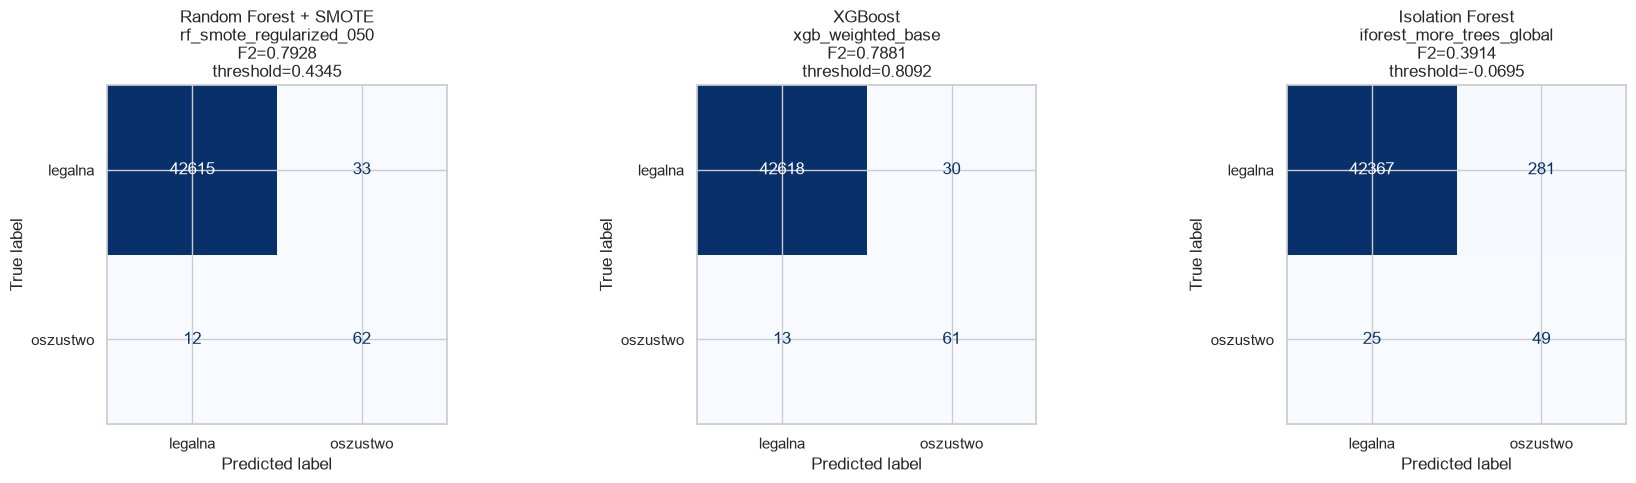

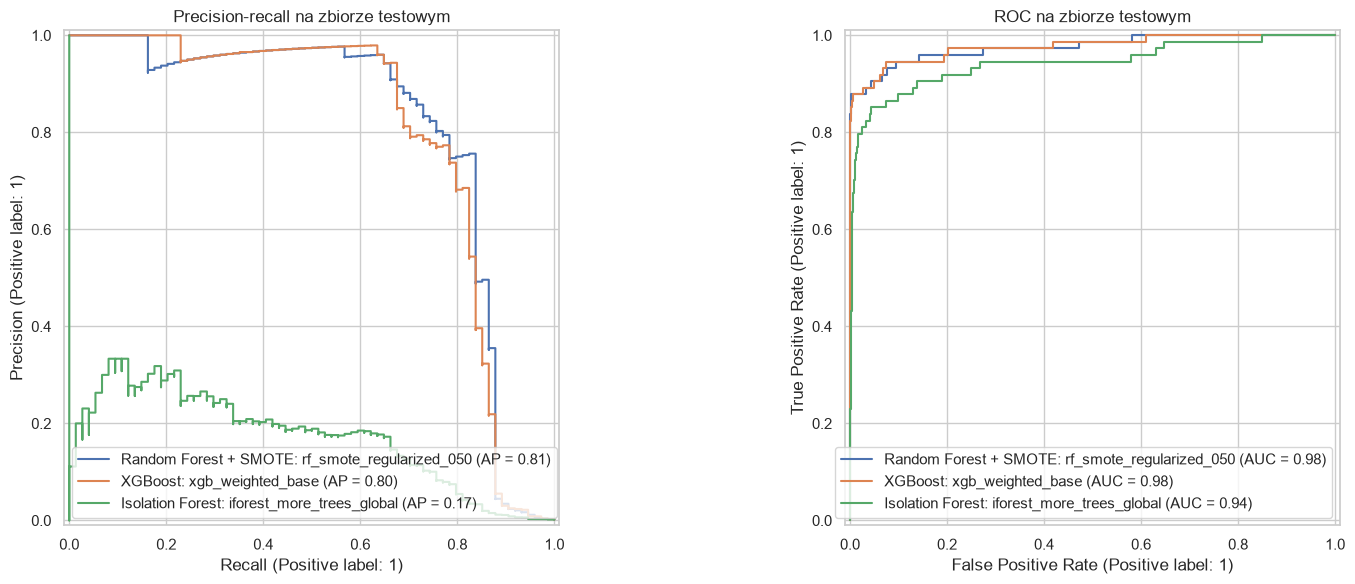

In [150]:
fig, axes = plt.subplots(1, len(test_outputs), figsize=(6 * len(test_outputs), 5))
axes = np.atleast_1d(axes)

for ax, (_, row) in zip(axes, test_results.iterrows()):
    model_name = row["model"]
    output = test_outputs[model_name]

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        output["y_pred"],
        display_labels=["legalna", "oszustwo"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(chr(10).join([
        row["category"],
        model_name,
        f"F2={row['f2']:.4f}",
        f"threshold={output['threshold']:.4f}",
    ]))

plt.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for _, row in test_results.iterrows():
    model_name = row["model"]
    output = test_outputs[model_name]
    curve_label = f"{row['category']}: {model_name}"

    PrecisionRecallDisplay.from_predictions(
        y_test,
        output["y_score"],
        name=curve_label,
        ax=axes[0],
    )
    RocCurveDisplay.from_predictions(
        y_test,
        output["y_score"],
        name=curve_label,
        ax=axes[1],
    )

axes[0].set_title("Precision-recall na zbiorze testowym")
axes[1].set_title("ROC na zbiorze testowym")
plt.tight_layout()

### Evaluation Notes

Precision, recall, F1, F2, PR-AUC and ROC-AUC are reported. F2 is the primary threshold-dependent metric because it gives more weight to recall, reducing missed fraud.

There is no strong evidence of overfitting, although hold-out test results are lower than the cross-validation mean. `rf_smote_regularized_050` has the highest mean CV F2 and slightly outperforms `xgb_weighted_base` on the test set (`0.7928` vs. `0.7881`).

Further risk can be reduced with simpler models, stronger regularisation, shallower trees, controlled oversampling and repeated validation. The hardest cases are frauds resembling legitimate transactions and unusual legitimate transactions flagged as suspicious.



# Conclusions

`rf_smote_regularized_050` is selected as the final model. It has the best validation F2 (`0.8750`) and the best hold-out test F2 (`0.7928`), with recall of `0.8378` and precision of `0.6526`. It also has the highest mean cross-validation F2, although `xgb_weighted_base` is close. The Wilcoxon test finds no statistically significant PR-AUC difference between those two models (`p-value = 0.0840`).

The main limitation is extreme class imbalance: fraud makes up only `0.173%` of the dataset and the test set contains only `74` fraud cases. Individual errors therefore noticeably affect precision, recall and F2. PCA-transformed features also limit business interpretability.

Useful next steps would include error analysis, time-based validation on newer transactions, threshold-stability checks and testing additional time features or an RF/XGBoost ensemble.

The model is a useful fraud-detection prototype, not a production-ready system. Deployment would require tests on newer data, performance and drift monitoring, and regular retraining.
